# Lensed LISA MBHB waveforms — step by step
All code is visible here and uses the same functions as the command-line scripts in `scripts/`
(`lisa_mbhb.workflow`). CPU only; kernel `lensing_gw`.

In [1]:
import os, sys
sys.path.insert(0, os.path.abspath('..') if os.path.basename(os.getcwd()) == 'Notebooks' else os.getcwd())
import numpy as np, matplotlib.pyplot as plt
from pycbc.waveform import fd_approximants
from lisa_mbhb import demo, noise, waveform as W, inference as I, lensing as L, workflow

/home/singh/miniconda3/lib/python3.13/importlib/__init__.py:88: UserWarning: Wswiglal-redir-stdio:

SWIGLAL standard output/error redirection is enabled in IPython.
This may lead to performance penalties. To disable locally, use:

with lal.no_swig_redirect_standard_output_error():
    ...

To disable globally, use:

lal.swig_redirect_standard_output_error(False)

Note however that this will likely lead to error messages from
LAL functions being either misdirected or lost when called from
Jupyter notebooks.

To suppress this warning, use:

import warnings
warnings.filterwarnings("ignore", "Wswiglal-redir-stdio")
import lal

  return _bootstrap._gcd_import(name[level:], package, level)
PyCBC.libutils: pkg-config call failed, setting NO_PKGCONFIG=1


## 1. Choose a waveform
PyCBC frequency-domain approximants available for aligned-spin MBHBs:

In [2]:
print([a for a in fd_approximants() if a.startswith('IMRPhenom') and not any(k in a for k in ('Tidal','INTERP','NSBH','P','C','B','A'))
       or a in ('IMRPhenomD','IMRPhenomHM','IMRPhenomXHM','IMRPhenomXAS')])

['IMRPhenomD', 'IMRPhenomHM', 'IMRPhenomXAS', 'IMRPhenomXHM']


## 2. Source and LISA signal
Source-frame masses + redshift → detector frame. The waveform is generated by PyCBC on an adaptive frequency grid, projected
with the finite-arm-length, orbit-dependent TDI response (A, E, T), and weighted by the SciRDv1 noise.

In [3]:
params = demo.default_params(m1=5e5, m2=2.5e5, z=1.0)    # detector-frame dict
print({k: (round(v, 3) if isinstance(v, float) else v) for k, v in params.items()})

inj = I.make_injection(params, W.WaveformConfig(approximant='IMRPhenomD', tc_ref=params['tc']))
f = inj.model.f
print(len(f), 'frequency points from', f[0], 'to', f[-1], 'Hz')

{'mass1': 1000000.0, 'mass2': 500000.0, 'spin1z': 0.3, 'spin2z': 0.1, 'distance': 6791.269, 'inclination': 0.9, 'coa_phase': 0.3, 'psi': 0.7, 'ecl_lon': 1.2, 'ecl_lat': 0.4, 'tc': 28401840.0}
103338 frequency points from 7.771092443474063e-05 to 0.03383738011628793 Hz


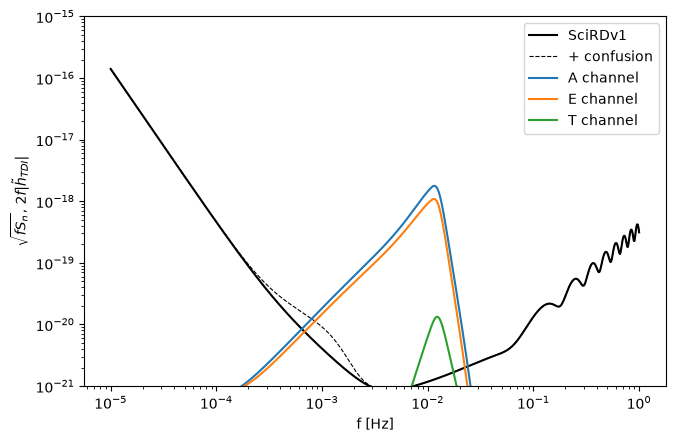

In [4]:
fg = np.logspace(-5, 0, 800)
fig, ax = plt.subplots(figsize=(7.5, 4.8))
ax.loglog(fg, np.sqrt(fg * noise.sensitivity_curve(fg)), 'k', label='SciRDv1')
ax.loglog(fg, np.sqrt(fg * noise.sensitivity_curve(fg, confusion=True)), 'k--', lw=.8, label='+ confusion')
for ch in 'AET':
    ax.loglog(f, 2 * f * np.abs(inj.signal[ch]), label=f'{ch} channel')
ax.set_ylim(1e-21, 1e-15); ax.set_xlabel('f [Hz]'); ax.set_ylabel(r'$\sqrt{fS_n}$, $2f|\tilde h_{TDI}|$'); ax.legend()
plt.show()

## 3. SNR
SNR² = Σ_channels 4 ∫ |h|²/S df. A and E dominate; T (null channel) is ~1%.

In [5]:
print('SNR =', round(inj.snr, 1), '   per channel:', {k: round(v, 1) for k, v in inj.snr_channels.items()})
comp = workflow.compare_approximants(params, ['IMRPhenomD', 'IMRPhenomHM', 'IMRPhenomXHM'])
for name, r in comp.items():
    print(f"{name:13s} SNR = {r['snr']:7.1f}   mismatch vs D = {r['mismatch_vs_ref']}")

SNR = 3376.5    per channel: {'A': 2733.8, 'E': 1981.6, 'T': 21.5}


IMRPhenomD    SNR =  3376.5   mismatch vs D = None
IMRPhenomHM   SNR =  3415.1   mismatch vs D = 0.01788674203084839
IMRPhenomXHM  SNR =  3402.8   mismatch vs D = 0.017797887708619897


## 4. Lens the signal with GWLENS
Point-mass lens: exact wave-optics F(w, y) from `gwlens.lens.point`, with `w = 8πG M_Lz f / c³`.
`LensedMBHB` multiplies h₊ and h× by F(f) before the LISA projection.

In [6]:
lens = L.PointMassLens(mass_lz=1e7, y=0.5)
sig = L.LensedMBHB(params, lens)
F = sig.amplification()
print('w range:', lens.w(sig.f[0]), '-', lens.w(sig.f[-1]))
print('SNR unlensed = %.0f, lensed = %.0f' % (sig.snr(lensed=False), sig.snr()))

w range: 0.09619919994948396 - 41.887661474250486


SNR unlensed = 3376, lensed = 4889


y=0.3: SNR 3376 -> 6710
y=0.5: SNR 3376 -> 4889
y=1.0: SNR 3376 -> 3881
y=2.0: SNR 3376 -> 3476


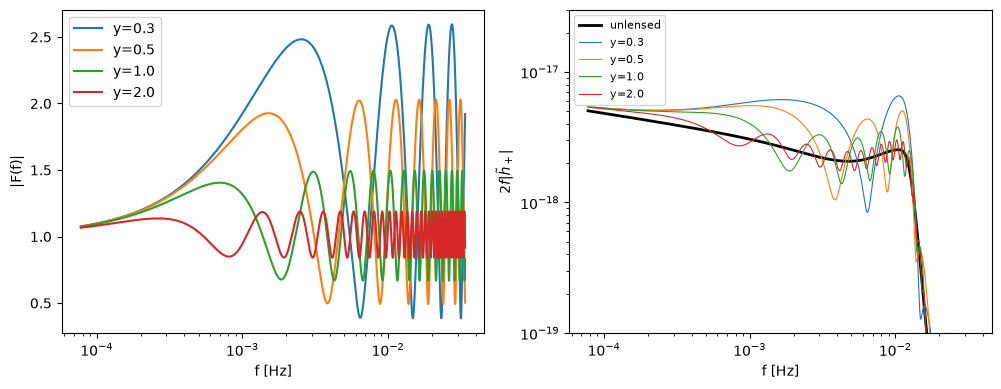

In [7]:
scan = workflow.lensed_snr_scan(params, 1e7, [0.3, 0.5, 1.0, 2.0])
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
hp0, _, _ = sig.polarizations(lensed=False)
ax[1].loglog(sig.f, 2 * sig.f * np.abs(hp0), 'k', lw=2, label='unlensed')
for y, r in scan.items():
    ax[0].semilogx(r['sig'].f, np.abs(r['F']), label=f'y={y}')
    ax[1].loglog(r['sig'].f, 2 * r['sig'].f * np.abs(r['hp']), lw=.8, label=f'y={y}')
    print(f"y={y}: SNR {r['snr_unlensed']:.0f} -> {r['snr']:.0f}")
ax[0].set(xlabel='f [Hz]', ylabel='|F(f)|'); ax[0].legend()
ax[1].set(xlabel='f [Hz]', ylabel=r'$2f|\tilde h_+|$', ylim=(1e-19, 3e-17)); ax[1].legend(fontsize=8)
plt.show()

## 5. Mismatch between lensed and unlensed signals
Mismatch = 1 − overlap, maximised over a global phase and a time shift. Small grid here; use
`python scripts/lisa_mbhb_03_mismatch.py` for the full one.

M_Lz=1e+07 y=0.5: mismatch=1.384e-01


M_Lz=1e+07 y=1.0: mismatch=6.536e-02


M_Lz=1e+07 y=2.0: mismatch=1.436e-02


M_Lz=1e+07 y=3.0: mismatch=4.688e-03


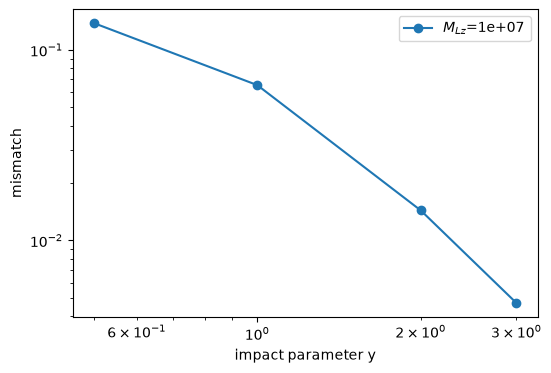

In [8]:
ys = [0.5, 1.0, 2.0, 3.0]
mm = workflow.mismatch_grid(params, [1e7], ys, cap=1001)
fig, ax = plt.subplots(figsize=(6, 4))
for M, vals in mm.items():
    ax.loglog(ys, vals, 'o-', label=f'$M_{{Lz}}$={M:.0e}')
ax.set(xlabel='impact parameter y', ylabel='mismatch'); ax.legend(); plt.show()

## Other lenses
`L.LookupTableLens('table.h5', w_of_f, y)` takes any GWLENS table (NFW, composite). Any object with an
`amplification(f)` method works with `LensedMBHB`.